In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
%matplotlib inline 

### Create a dataset
### Here we create a arfitical dataset for X(input fecture) and y(Output )

### Feacture selection 

In [13]:
X=6*np.random.rand(100,1)-3

In [15]:
y=0.5 * X**2 + 1.5*X +2 + np.random.randn(100,1)

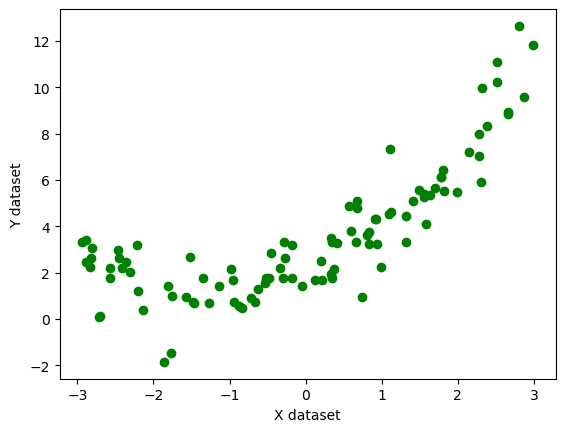

Text(0, 0.5, 'Y dataset')

In [22]:
plt.scatter(X,y,color='g')
plt.show()
plt.xlabel("X dataset")
plt.ylabel("Y dataset")

### Train_test_split

In [37]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [40]:
X_test.shape
# X_train.shape
# y_train.shape
y_test.shape

(20, 1)

## Make polynomial regression model and the train by .fit() fun

### Lets implement Simple Linear Regression


In [45]:
from sklearn.linear_model import LinearRegression
regression_linear=LinearRegression()

In [46]:
regression_linear

LinearRegression()

In [48]:
regression_linear.fit(X_train,y_train)

LinearRegression()

### predication for LinearRegression

In [49]:
y_lin_pred=regression_linear.predict(X_test)

In [53]:
print(y_lin_pred)

[[0.60209064]
 [5.59141627]
 [2.88956078]
 [6.63942156]
 [3.73652325]
 [5.62875952]
 [6.21707544]
 [2.87896683]
 [5.59311432]
 [6.80623155]
 [1.71682751]
 [4.57675138]
 [0.10591068]
 [4.48815819]
 [1.41749429]
 [5.42802527]
 [6.47070804]
 [2.76614814]
 [0.98685502]
 [4.30422949]]


### Model Evaluation R2-score for lingear_regg

In [56]:
from sklearn.metrics import r2_score
score=r2_score(y_test,regression_linear.predict(X_test))
score

0.6137555630723113

### let visulize this linger reg model 



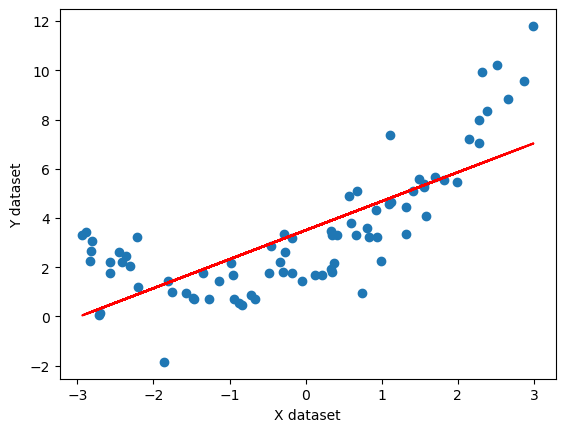

In [62]:
plt.plot(X_train,regression_linear.predict(X_train),color='r')
plt.scatter(X_train,y_train)
plt.xlabel("X dataset")
plt.ylabel("Y dataset")
plt.show()

## Apply polynomial regression on this non_linear data

In [70]:
from sklearn.preprocessing import PolynomialFeatures 

In [79]:
poly_reg=PolynomialFeatures(degree=2,include_bias=True)
X_train_poly=poly_reg.fit_transform(X_train)
X_test_poly=poly_reg.transform(X_test)

In [80]:
poly_reg

PolynomialFeatures()

In [88]:
X_test_poly.shape

(20, 3)

### Model Evalucation R2 score for polynomial reg

In [93]:
from sklearn.metrics import r2_score
regression=LinearRegression()
regression.fit(X_train_poly,y_train)
y_pred=regression.predict(X_test_poly)
score=r2_score(y_test,y_pred)
score

0.8640295911541663

In [99]:
print(regression.coef_)

[[0.         1.37578721 0.5146441 ]]


In [101]:
print(regression.intercept_)

[2.10288486]


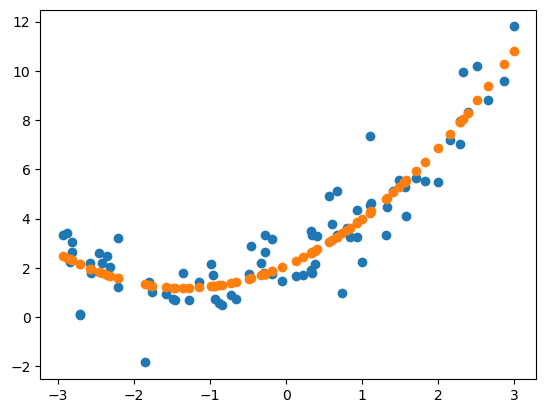

In [110]:
plt.scatter(X_train,y_train)
plt.scatter(X_train,regression.predict(X_train_poly))
plt.show()

In [111]:
poly=PolynomialFeatures(degree=3,include_bias=True)
X_train_poly=poly.fit_transform(X_train)
X_test_poly=poly.transform(X_test)

In [116]:
# X_train_poly  array([[ 1.00000000e+00, -7.20068605e-01,  5.18498796e-01,
#                        -3.73354704e-01]]),.....

In [117]:
from sklearn.metrics import r2_score
regression = LinearRegression()
regression.fit(X_train_poly, y_train)
y_pred = regression.predict(X_test_poly)
score=r2_score(y_test,y_pred)
print(score)

0.8641268913208755


## Prediction of new data set

In [121]:
#3 Prediction of new data set
X_new = np.linspace(-3, 3, 200).reshape(200, 1)
X_new_poly = poly.transform(X_new)

# X_new_poly
# output
#         array([[ 1.00000000e+00, -3.00000000e+00,  9.00000000e+00,
#                -2.70000000e+01],..])

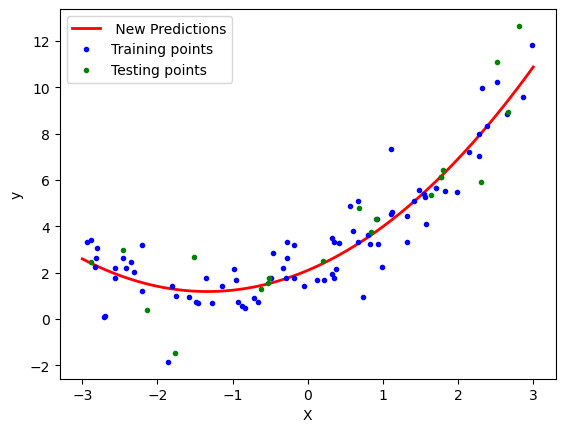

In [119]:
y_new = regression.predict(X_new_poly)
plt.plot(X_new, y_new, "r-", linewidth=2, label=" New Predictions")
plt.plot(X_train, y_train, "b.",label='Training points')
plt.plot(X_test, y_test, "g.",label='Testing points')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

## Pipeline Concepts 

In [122]:
from sklearn.pipeline import Pipeline

In [126]:
def poly_regression(degree):
    X_new = np.linspace(-3, 3, 200).reshape(200, 1)
    
    poly_features=PolynomialFeatures(degree=degree,include_bias=True)
    lin_reg=LinearRegression()
    poly_regression=Pipeline([
        ("poly_features",poly_features),
        ("lin_reg",lin_reg)
    ])
    poly_regression.fit(X_train,y_train) ## ploynomial and fit of linear reression
    y_pred_new=poly_regression.predict(X_new)
    #plotting prediction line
    plt.plot(X_new, y_pred_new,'r', label="Degree " + str(degree), linewidth=2)
    plt.plot(X_train, y_train, "b.", linewidth=3)
    plt.plot(X_test, y_test, "g.", linewidth=3)
    plt.legend(loc="upper left")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.axis([-4,4, 0, 10])
    plt.show()
    